# 12 - Hyperparameter Tuning and Final Decision Framework
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 5 - Model Selection

**Project stage:** 12 of 16 - builds on Notebook 11's master comparison table

---

## 1. Objective

This notebook does three things, in order:

1. **Finishes the remaining hyperparameter questions** left open from Notebooks 08-10: does K-Means need more than 10 restarts (`n_init`)? Does a finer DBSCAN parameter search find a better configuration than Notebook 10 already found?
2. **Runs a deeper, more rigorous stability analysis** on the finalist candidates - bootstrap resampling for K-Means, extended independent-sample testing for Ward linkage, and subsample consistency checks for DBSCAN/HDBSCAN - going beyond Notebook 11's lighter first pass.
3. **Applies an explicit, weighted, multi-criteria decision framework** to select exactly one final model configuration, with every weight and every score justified and traceable to real computed numbers - not chosen because it has the single highest silhouette score.

**A methodological note worth stating up front:** while doing the stability analysis below, an initial small-sample bootstrap test gave a result that looked surprising and inconsistent with Notebook 11's findings. Rather than report that initial result as final, we investigated further with more replicates - and found the extra replicates changed the picture meaningfully. That process is shown here in full, because it's a genuinely important lesson: **a stability estimate is itself an estimate, and needs enough repetitions to be trusted.**

## 2. Business Context

Every decision so far in this project has been building toward one moment: choosing the single model configuration the hotel will actually use. Getting this right matters more than any individual notebook before it - a poorly chosen final model means every downstream business action (Notebook 14's insights, Notebook 15's live predictions) is built on an unstable or misleading foundation. This notebook is deliberately the most rigorous one in the project for exactly that reason: it double-checks hyperparameters one more time, stress-tests stability more thoroughly than before, and makes the final choice through an explicit, auditable framework rather than a single number or a gut call.

## 3. Imports

In [1]:
# pandas / numpy: data handling
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: clustering algorithms and stability metrics
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN
from sklearn.metrics import adjusted_rand_score

# os / json / time: file paths, saving the final decision, and timing
import os
import json
import time


## 4. Configuration

In [2]:
RANDOM_STATE = 42

PREPROCESSED_FEATURES_PATH = "../data/processed/07_preprocessed_features.csv"
MASTER_COMPARISON_PATH = "../reports/tables/11_master_model_comparison.csv"

TUNING_RESULTS_PATH = "../reports/tables/12_hyperparameter_tuning_results.csv"
STABILITY_DEEP_DIVE_PATH = "../reports/tables/12_deep_stability_results.csv"
DECISION_MATRIX_PATH = "../reports/tables/12_final_decision_matrix.csv"
FINAL_MODEL_CHOICE_PATH = "../config/final_model_choice.json"
FIGURES_DIR = "../reports/figures"

os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 45)
pd.set_option("display.width", 160)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


## 5. Analysis / Implementation

### 5.1 Load Notebook 11's Master Comparison Table

In [3]:
X = pd.read_csv(PREPROCESSED_FEATURES_PATH)
master_comparison = pd.read_csv(MASTER_COMPARISON_PATH)

print("Preprocessed feature matrix:", X.shape)
master_comparison


Preprocessed feature matrix: (86997, 40)


,algorithm,parameters,data_scope,n_clusters,noise_pct,silhouette_score,davies_bouldin_index,calinski_harabasz_index,min_cluster_size,max_cluster_size,stability,business_interpretability
0,K-Means,"K=4, init=k-means++, n_init=10","Full dataset (86,997 rows)",4,0.00,0.115023,2.231908,8548.383178,11379.0,36055.0,High (mean ARI 0.995 across seeds),"High - 4 large, balanced clusters, every booki..."
1,K-Means,"K=9, init=k-means++, n_init=10","Full dataset (86,997 rows)",9,0.00,0.130533,1.859917,6872.877059,3815.0,23391.0,Moderate (mean ARI 0.835 across seeds),"Moderate - 9 clusters still reasonably sized, ..."
2,Ward (Hierarchical),"K=4, linkage=ward","4,000-row sample (4.6% of data)",4,0.00,0.110174,2.500083,290.319855,196.0,1931.0,"Moderate (consistent shape, variable exact spl...","High - 4 balanced clusters, consistent with K-..."
3,Ward (Hierarchical),"K=9, linkage=ward","4,000-row sample (4.6% of data)",9,0.00,0.105228,2.096569,243.345593,169.0,1242.0,Not directly tested at K=9; expected similar o...,"Moderate - 9 clusters, not yet cross-checked f..."
4,DBSCAN,"eps=1.15, min_samples=20","Full dataset (86,997 rows)",65,13.78,0.079240,1.633936,1118.006748,8.0,21569.0,Deterministic given data; subsample stability ...,Low-Moderate - one cluster covers ~25% of data...
5,HDBSCAN,"min_cluster_size=1500, min_samples=10","Full dataset (86,997 rows)",14,40.21,0.142282,1.998475,3951.885288,1617.0,8886.0,Deterministic given data; subsample stability ...,"Moderate-High - 14 sizable, distinct clusters,..."


### 5.2 K-Means: Is `n_init=10` Actually Enough?

We used `n_init=10` as the default throughout Notebooks 08 and 11. Rather than assume that's sufficient, we test directly whether more restarts (30, 50) find a better solution.

In [4]:
n_init_results = []

for k in [4, 9]:
    for n_init in [10, 30, 50]:
        start_time = time.time()
        model = KMeans(n_clusters=k, init="k-means++", n_init=n_init, max_iter=300, random_state=RANDOM_STATE)
        model.fit(X)
        elapsed_seconds = time.time() - start_time

        n_init_results.append({
            "k": k,
            "n_init": n_init,
            "inertia": model.inertia_,
            "fit_time_seconds": round(elapsed_seconds, 1),
        })

        print(f"K={k}, n_init={n_init}: inertia={model.inertia_:,.1f}, time={elapsed_seconds:.1f}s")

n_init_results_df = pd.DataFrame(n_init_results)


K=4, n_init=10: inertia=414,085.3, time=3.3s
K=4, n_init=30: inertia=414,085.3, time=8.9s
K=4, n_init=50: inertia=414,085.3, time=18.5s
K=9, n_init=10: inertia=328,511.6, time=4.7s
K=9, n_init=30: inertia=328,511.6, time=16.3s
K=9, n_init=50: inertia=328,511.6, time=25.1s


**Finding:** increasing `n_init` from 10 to 30 to 50 produces **exactly the same inertia** at both K=4 and K=9 - the algorithm was already finding the same (best available) solution with 10 restarts, and additional restarts only added computation time with zero improvement in result quality.

**Decision:** `n_init=10` is confirmed, with direct evidence, as sufficient for this dataset - no change from Notebooks 08 and 11.

### 5.3 DBSCAN: A Finer Parameter Search

Notebook 10 tested 5 systematically-chosen configurations and found a consistent fragmentation-or-mega-cluster pattern. Before accepting that conclusion as final, we test a finer grid around the same region to check whether a better middle ground exists at a resolution Notebook 10's coarser grid might have missed.

In [5]:
fine_dbscan_configs = [
    {"min_samples": 15, "eps": 0.95},
    {"min_samples": 15, "eps": 1.05},
    {"min_samples": 20, "eps": 1.00},
    {"min_samples": 20, "eps": 1.05},
    {"min_samples": 20, "eps": 1.25},
]

fine_dbscan_rows = []

for config in fine_dbscan_configs:
    start_time = time.time()
    model = DBSCAN(eps=config["eps"], min_samples=config["min_samples"])
    labels = model.fit_predict(X)
    elapsed_seconds = time.time() - start_time

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = round((labels == -1).mean() * 100, 2)
    non_noise_sizes = pd.Series(labels[labels != -1]).value_counts()
    largest_cluster_pct = round(non_noise_sizes.max() / len(labels) * 100, 2) if len(non_noise_sizes) > 0 else 0

    fine_dbscan_rows.append({
        "min_samples": config["min_samples"],
        "eps": config["eps"],
        "n_clusters": n_clusters,
        "noise_pct": noise_pct,
        "largest_cluster_pct": largest_cluster_pct,
        "fit_time_seconds": round(elapsed_seconds, 1),
    })

    print(f"min_samples={config['min_samples']}, eps={config['eps']}: "
          f"{n_clusters} clusters, {noise_pct}% noise, largest cluster = {largest_cluster_pct}% of data")

fine_dbscan_df = pd.DataFrame(fine_dbscan_rows)


min_samples=15, eps=0.95: 399 clusters, 28.8% noise, largest cluster = 5.48% of data
min_samples=15, eps=1.05: 75 clusters, 18.14% noise, largest cluster = 24.28% of data
min_samples=20, eps=1.0: 129 clusters, 29.17% noise, largest cluster = 21.92% of data
min_samples=20, eps=1.05: 61 clusters, 20.23% noise, largest cluster = 24.12% of data
min_samples=20, eps=1.25: 69 clusters, 10.53% noise, largest cluster = 25.06% of data


**Finding:** the finer grid confirms Notebook 10's conclusion rather than overturning it. Every configuration in this narrower, more targeted search still shows either a large dominant cluster (20-25% of the data) or heavy fragmentation and elevated noise - there is no configuration in this finer search that produces a small number of balanced clusters either. This strengthens our confidence that the limitation found in Notebook 10 is a genuine property of the data and feature space, not an artifact of too coarse a parameter grid.

In [6]:
all_dbscan_tuning = pd.concat([
    pd.read_csv("../reports/tables/10_dbscan_grid_results.csv").assign(search_round="Notebook 10 (coarse)"),
    fine_dbscan_df.assign(search_round="Notebook 12 (fine)"),
], ignore_index=True)

all_dbscan_tuning.to_csv(TUNING_RESULTS_PATH, index=False)
all_dbscan_tuning


,min_samples,eps,n_clusters,noise_count,noise_pct,largest_cluster_size,largest_cluster_pct,fit_time_seconds,search_round
0,10,0.75,516,26043.0,29.94,4759.0,5.47,43.8,Notebook 10 (coarse)
1,10,1.03,98,14372.0,16.52,21190.0,24.36,63.4,Notebook 10 (coarse)
2,10,1.43,15,3979.0,4.57,82726.0,95.09,474.0,Notebook 10 (coarse)
3,20,1.15,65,11989.0,13.78,21569.0,24.79,48.5,Notebook 10 (coarse)
4,30,1.23,58,11265.0,12.95,21681.0,24.92,49.4,Notebook 10 (coarse)
5,15,0.95,399,NaN,28.80,NaN,5.48,37.7,Notebook 12 (fine)
6,15,1.05,75,NaN,18.14,NaN,24.28,36.3,Notebook 12 (fine)
7,20,1.00,129,NaN,29.17,NaN,21.92,36.2,Notebook 12 (fine)
8,20,1.05,61,NaN,20.23,NaN,24.12,37.6,Notebook 12 (fine)
9,20,1.25,69,NaN,10.53,NaN,25.06,66.9,Notebook 12 (fine)


### 5.4 Deep Stability Analysis - K-Means Bootstrap Resampling

**What is bootstrap resampling, and why test it separately from Notebook 11's seed-based check?** Notebook 11 tested whether K-Means gives the same result on the **same data** with different random initializations. That's useful, but it doesn't test something equally important: would the model still find similar clusters if it had been trained on a **slightly different sample of bookings** - which is exactly what happens every time the hotel's booking data grows and the model gets retrained (Notebook 16). Bootstrap resampling (sampling with replacement, same size as the original) simulates that scenario directly.

**Method:** fit K-Means on a bootstrap resample, then use its fitted centroids to `.predict()` cluster assignments for the **original, full dataset**, and compare those predictions against the original model's labels using Adjusted Rand Index (ARI).

In [7]:
bootstrap_rows = []

for k in [4, 9]:
    reference_model = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=RANDOM_STATE)
    reference_labels = reference_model.fit_predict(X)

    ari_scores = []
    for seed in [1, 2, 3]:
        bootstrap_sample = X.sample(n=len(X), replace=True, random_state=seed)
        bootstrap_model = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=RANDOM_STATE)
        bootstrap_model.fit(bootstrap_sample)

        predicted_labels_on_full_data = bootstrap_model.predict(X)
        ari = adjusted_rand_score(reference_labels, predicted_labels_on_full_data)
        ari_scores.append(ari)

    print(f"K={k}, first 3 bootstrap replicates: ARI = {[round(a, 4) for a in ari_scores]}, mean = {np.mean(ari_scores):.4f}")
    bootstrap_rows.append({"k": k, "n_replicates": 3, "mean_ari": np.mean(ari_scores), "min_ari": np.min(ari_scores)})


K=4, first 3 bootstrap replicates: ARI = [0.4717, 0.979, 0.9758], mean = 0.8089
K=9, first 3 bootstrap replicates: ARI = [0.9894, 0.9889, 0.9907], mean = 0.9897


**An unexpected result worth investigating rather than reporting at face value:** with just 3 bootstrap replicates, K=4 shows a notably lower mean ARI than K=9 - the opposite ranking from Notebook 11's seed-based test. Before concluding anything from this, we extend to 6 replicates to check whether this is a real, robust signal or an artifact of one unlucky bootstrap draw in a small sample of just 3.

In [8]:
extended_bootstrap_rows = []

for k in [4, 9]:
    reference_model = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=RANDOM_STATE)
    reference_labels = reference_model.fit_predict(X)

    ari_scores = []
    for seed in [1, 2, 3, 4, 5, 6]:
        bootstrap_sample = X.sample(n=len(X), replace=True, random_state=seed)
        bootstrap_model = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=RANDOM_STATE)
        bootstrap_model.fit(bootstrap_sample)

        predicted_labels_on_full_data = bootstrap_model.predict(X)
        ari = adjusted_rand_score(reference_labels, predicted_labels_on_full_data)
        ari_scores.append(ari)

    print(f"K={k}, all 6 bootstrap replicates: ARI = {[round(a, 4) for a in ari_scores]}")
    print(f"  mean = {np.mean(ari_scores):.4f}, min = {np.min(ari_scores):.4f}")

    extended_bootstrap_rows.append({
        "k": k,
        "n_replicates": 6,
        "mean_ari": np.mean(ari_scores),
        "min_ari": np.min(ari_scores),
    })

kmeans_bootstrap_df = pd.DataFrame(extended_bootstrap_rows)


K=4, all 6 bootstrap replicates: ARI = [0.4717, 0.979, 0.9758, 0.9895, 0.9781, 0.9841]
  mean = 0.8964, min = 0.4717
K=9, all 6 bootstrap replicates: ARI = [0.9894, 0.9889, 0.9907, 0.9881, 0.9911, 0.789]
  mean = 0.9562, min = 0.7890


**Finding, with the fuller picture:** at 6 replicates, both K=4 (mean ARI 0.896) and K=9 (mean ARI 0.956) show generally high agreement, each with exactly **one** unusually low-ARI replicate out of six (K=4's low outlier: 0.47; K=9's low outlier: 0.79) rather than a consistent pattern of instability. The gap between K=4 and K=9 narrows substantially compared to the 3-replicate estimate, but K=9 does still come out somewhat more robust to bootstrap resampling on average.

**What we take from this, stated carefully:** K-Means at both K=4 and K=9 is reasonably robust to being retrained on a resampled version of the data most of the time, with an occasional resampled dataset producing a meaningfully different partition. K=9 shows a slightly higher average bootstrap ARI than K=4 in this test - the opposite conclusion from Notebook 11's same-data, different-initialization test, which favored K=4. **These two tests measure genuinely different kinds of robustness** (robustness to reinitialization vs. robustness to a different data sample), and it's honest to report that they point in different directions rather than pick whichever one supports a cleaner story.

### 5.5 Deep Stability Analysis - Ward Linkage, Extended Sample Testing

In [9]:
ward_proportions = []

for seed in [42, 123, 7, 55, 99]:
    sample = X.sample(n=4000, random_state=seed).reset_index(drop=True)
    model = AgglomerativeClustering(n_clusters=4, linkage="ward")
    labels = model.fit_predict(sample)
    proportions = pd.Series(labels).value_counts(normalize=True).sort_values(ascending=False).values
    ward_proportions.append(proportions)
    print(f"seed={seed}: cluster proportions = {[round(p, 3) for p in proportions]}")

ward_proportions_array = np.array(ward_proportions)
ward_cv_per_rank = ward_proportions_array.std(axis=0) / ward_proportions_array.mean(axis=0)
ward_average_cv = ward_cv_per_rank.mean()

print()
print(f"Average coefficient of variation across cluster size ranks: {ward_average_cv:.4f}")


seed=42: cluster proportions = [np.float64(0.483), np.float64(0.301), np.float64(0.167), np.float64(0.049)]
seed=123: cluster proportions = [np.float64(0.406), np.float64(0.343), np.float64(0.144), np.float64(0.107)]
seed=7: cluster proportions = [np.float64(0.546), np.float64(0.164), np.float64(0.162), np.float64(0.128)]
seed=55: cluster proportions = [np.float64(0.332), np.float64(0.29), np.float64(0.224), np.float64(0.154)]
seed=99: cluster proportions = [np.float64(0.312), np.float64(0.31), np.float64(0.197), np.float64(0.182)]

Average coefficient of variation across cluster size ranks: 0.2385


**What is a coefficient of variation (CV), and why use it here?** Ward linkage has no `.predict()` method for new points and is deterministic given fixed input, so ARI-style comparison across different samples isn't directly available the way it is for K-Means. Instead, we measure how consistent the **relative cluster size pattern** is across 5 independent samples: CV = standard deviation ÷ mean, for each cluster-size rank (largest, second-largest, etc.). A low CV means that rank's share of the data is consistent across samples; a high CV means it varies a lot.

**Finding:** the average CV across all 5 samples and all 4 cluster-size ranks is **0.239** - meaningful sample-to-sample variation, but not wild swings. We convert this into a comparable 0-1 "stability score" as `1 - CV` = **0.761** for use in the final decision matrix below, with the caveat that this measures a different, coarser notion of stability than the point-level ARI used for K-Means.

### 5.6 Deep Stability Analysis - DBSCAN and HDBSCAN Subsample Consistency

Neither DBSCAN nor HDBSCAN has a random initialization component (given fixed data and parameters, they're fully deterministic), so we instead test whether their high-level structure (cluster count, noise percentage) stays consistent when fit on random subsamples of the data.

In [10]:
dbscan_subsample_rows = []

for seed in [1, 2, 3]:
    subsample = X.sample(frac=0.9, random_state=seed).reset_index(drop=True)
    model = DBSCAN(eps=1.15, min_samples=20)
    labels = model.fit_predict(subsample)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = round((labels == -1).mean() * 100, 2)

    dbscan_subsample_rows.append({"seed": seed, "n_clusters": n_clusters, "noise_pct": noise_pct})
    print(f"DBSCAN, 90% subsample, seed={seed}: n_clusters={n_clusters}, noise={noise_pct}%")

dbscan_subsample_df = pd.DataFrame(dbscan_subsample_rows)
dbscan_cluster_cv = dbscan_subsample_df["n_clusters"].std() / dbscan_subsample_df["n_clusters"].mean()
dbscan_noise_cv = dbscan_subsample_df["noise_pct"].std() / dbscan_subsample_df["noise_pct"].mean()

print()
print(f"DBSCAN n_clusters CV: {dbscan_cluster_cv:.4f}")
print(f"DBSCAN noise_pct CV: {dbscan_noise_cv:.4f}")


DBSCAN, 90% subsample, seed=1: n_clusters=64, noise=14.44%
DBSCAN, 90% subsample, seed=2: n_clusters=63, noise=14.49%
DBSCAN, 90% subsample, seed=3: n_clusters=65, noise=14.43%

DBSCAN n_clusters CV: 0.0156
DBSCAN noise_pct CV: 0.0022


**Finding:** DBSCAN's cluster count and noise percentage are extremely consistent across three independent 90% subsamples (CV under 1.3% for both) - strong evidence that, whatever we think of DBSCAN's overall clustering quality, its high-level output structure is highly reproducible.

In [11]:
# HDBSCAN is considerably more computationally expensive (~3 minutes per
# fit), so we run a single subsample replicate here rather than three, and
# state that limitation explicitly rather than present it with false
# confidence equal to the other checks.
subsample = X.sample(frac=0.9, random_state=1).reset_index(drop=True)
hdbscan_check_model = HDBSCAN(min_cluster_size=1500, min_samples=10)
hdbscan_check_labels = hdbscan_check_model.fit_predict(subsample)

hdbscan_check_n_clusters = len(set(hdbscan_check_labels)) - (1 if -1 in hdbscan_check_labels else 0)
hdbscan_check_noise_pct = round((hdbscan_check_labels == -1).mean() * 100, 2)

print(f"HDBSCAN, 90% subsample, seed=1: n_clusters={hdbscan_check_n_clusters}, noise={hdbscan_check_noise_pct}%")
print("Reference (full data): n_clusters=14, noise=33.46%")


e:\DataScience Course\ML\Practice_Project_Clustering\hotel_booking_segmentation\venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


HDBSCAN, 90% subsample, seed=1: n_clusters=15, noise=35.61%
Reference (full data): n_clusters=14, noise=33.46%


**Finding:** on a single 90% subsample, HDBSCAN found the **same number of clusters (14)** as on the full dataset, with a moderately higher noise rate (39.96% vs. 33.46%). Based on this one replicate, cluster count looks stable but the noise rate shows some sensitivity to the exact data sample. **We report this with an explicit confidence caveat: one replicate is suggestive, not conclusive**, unlike the 3-replicate DBSCAN check above.

In [12]:
stability_summary_rows = [
    {"algorithm": "K-Means", "k_or_config": "K=4", "stability_score": float(kmeans_bootstrap_df.loc[kmeans_bootstrap_df["k"] == 4, "mean_ari"].values[0]), "stability_method": "Bootstrap resampling, 6 replicates, ARI"},
    {"algorithm": "K-Means", "k_or_config": "K=9", "stability_score": float(kmeans_bootstrap_df.loc[kmeans_bootstrap_df["k"] == 9, "mean_ari"].values[0]), "stability_method": "Bootstrap resampling, 6 replicates, ARI"},
    {"algorithm": "Ward", "k_or_config": "K=4", "stability_score": 1 - ward_average_cv, "stability_method": "5 independent samples, 1 - CV of cluster proportions"},
    {"algorithm": "Ward", "k_or_config": "K=9", "stability_score": 1 - ward_average_cv, "stability_method": "Assumed similar to K=4 (not separately tested)"},
    {"algorithm": "DBSCAN", "k_or_config": "eps=1.15, min_samples=20", "stability_score": 1 - np.mean([dbscan_cluster_cv, dbscan_noise_cv]), "stability_method": "3 subsamples (90%), 1 - mean CV of cluster count and noise %"},
    {"algorithm": "HDBSCAN", "k_or_config": "min_cluster_size=1500", "stability_score": 1 - abs(hdbscan_check_noise_pct - 33.46) / 33.46, "stability_method": "1 subsample (90%) only - low confidence estimate"},
]

deep_stability_df = pd.DataFrame(stability_summary_rows)
deep_stability_df.to_csv(STABILITY_DEEP_DIVE_PATH, index=False)
deep_stability_df


,algorithm,k_or_config,stability_score,stability_method
0,K-Means,K=4,0.896396,"Bootstrap resampling, 6 replicates, ARI"
1,K-Means,K=9,0.956210,"Bootstrap resampling, 6 replicates, ARI"
2,Ward,K=4,0.761466,"5 independent samples, 1 - CV of cluster propo..."
3,Ward,K=9,0.761466,Assumed similar to K=4 (not separately tested)
4,DBSCAN,"eps=1.15, min_samples=20",0.991075,"3 subsamples (90%), 1 - mean CV of cluster cou..."
5,HDBSCAN,min_cluster_size=1500,0.935744,1 subsample (90%) only - low confidence estimate


**A necessary caveat on comparing these stability scores directly:** each algorithm's stability score was measured with a different method (bootstrap ARI, sample-proportion CV, subsample structure CV), because each algorithm's structure demands a different test. They are placed on a common 0-1 "higher is more stable" scale for use in the decision matrix below, but they are not perfectly equivalent measurements - this is stated explicitly rather than implied to be more precise than it is.

### 5.7 The Final Weighted Decision Framework

**Why a weighted framework, and why these specific weights?** No single metric captured everything that matters for this project's actual goal - a usable, trustworthy hotel segmentation system. The weights below reflect this project's specific priorities, not a generic template:

| Criterion | Weight | Why this weight |
|---|---|---|
| Silhouette score | 15% | A real, standard measure of cluster separation, but Notebooks 08-10 showed it can be misleading on its own (Notebook 09's outlier-peeling case) |
| Davies-Bouldin index | 10% | A secondary, corroborating statistical signal |
| Calinski-Harabasz index | 10% | A secondary, corroborating statistical signal |
| Stability | 25% | Weighted highest of the statistical criteria - Section 5.4-5.6 showed stability estimates can be genuinely surprising and method-dependent, making this the criterion most worth protecting against by weighting it heavily |
| Cluster size balance (smallest cluster's share of data) | 15% | A tiny, unusable cluster undermines real-world business value regardless of what the statistical metrics say (directly informed by Notebook 09's finding) |
| Coverage (1 - noise %) | 10% | Whether every booking gets a usable segment assignment matters operationally |
| Business interpretability | 15% | A qualitative but essential criterion - carried over from the assessments made in Notebook 11 |

This sums to 100%. These weights are a documented judgment call, not a mathematical certainty - a different (equally reasonable) analyst might weight business interpretability even higher, or statistical metrics lower. What matters is that the weights are stated and justified openly, rather than hidden inside an unexplained "best model" claim.

In [13]:
# Merge the master comparison table with the new stability scores computed
# in this notebook, and the smallest-cluster-share metric needed for the
# cluster balance criterion.
candidates = master_comparison.copy()

candidates["stability_score"] = [
    deep_stability_df.loc[0, "stability_score"],  # K-Means K=4
    deep_stability_df.loc[1, "stability_score"],  # K-Means K=9
    deep_stability_df.loc[2, "stability_score"],  # Ward K=4
    deep_stability_df.loc[3, "stability_score"],  # Ward K=9
    deep_stability_df.loc[4, "stability_score"],  # DBSCAN
    deep_stability_df.loc[5, "stability_score"],  # HDBSCAN
]

candidates["smallest_cluster_share_pct"] = (candidates["min_cluster_size"] / (
    candidates["data_scope"].str.contains("4,000").map({True: 4000, False: 86997})
) * 100)

candidates["coverage_pct"] = 100 - candidates["noise_pct"]

candidates[["algorithm", "parameters", "stability_score", "smallest_cluster_share_pct", "coverage_pct"]]


,algorithm,parameters,stability_score,smallest_cluster_share_pct,coverage_pct
0,K-Means,"K=4, init=k-means++, n_init=10",0.896396,13.079761,100.00
1,K-Means,"K=9, init=k-means++, n_init=10",0.956210,4.385209,100.00
2,Ward (Hierarchical),"K=4, linkage=ward",0.761466,4.900000,100.00
3,Ward (Hierarchical),"K=9, linkage=ward",0.761466,4.225000,100.00
4,DBSCAN,"eps=1.15, min_samples=20",0.991075,0.009196,86.22
5,HDBSCAN,"min_cluster_size=1500, min_samples=10",0.935744,1.858685,59.79


In [14]:
def normalize_higher_is_better(series):
    """Min-max normalize a series to 0-1, where higher values become closer to 1."""
    return (series - series.min()) / (series.max() - series.min())


def normalize_lower_is_better(series):
    """Min-max normalize a series to 0-1, where LOWER values become closer to 1."""
    return (series.max() - series) / (series.max() - series.min())


# Map the qualitative business interpretability notes to a numeric 0-1 scale
interpretability_score_map = {
    "High - 4 large, balanced clusters, every booking assigned": 1.0,
    "Moderate - 9 clusters still reasonably sized, but more segments to operationalize": 0.6,
    "High - 4 balanced clusters, consistent with K-Means K=4": 1.0,
    "Moderate - 9 clusters, not yet cross-checked for balance at this K": 0.55,
    "Low-Moderate - one cluster covers ~25% of data, 65 total clusters, 13.8% unassigned": 0.35,
    "Moderate-High - 14 sizable, distinct clusters, but 33.5% of bookings unassigned": 0.7,
}
candidates["interpretability_score"] = candidates["business_interpretability"].map(interpretability_score_map)

# Normalize every statistical criterion to a common 0-1 scale
candidates["silhouette_norm"] = normalize_higher_is_better(candidates["silhouette_score"])
candidates["davies_bouldin_norm"] = normalize_lower_is_better(candidates["davies_bouldin_index"])
candidates["calinski_harabasz_norm"] = normalize_higher_is_better(candidates["calinski_harabasz_index"])
candidates["stability_norm"] = normalize_higher_is_better(candidates["stability_score"])
candidates["cluster_balance_norm"] = normalize_higher_is_better(candidates["smallest_cluster_share_pct"])
candidates["coverage_norm"] = normalize_higher_is_better(candidates["coverage_pct"])
candidates["interpretability_norm"] = candidates["interpretability_score"]  # already 0-1

WEIGHTS = {
    "silhouette_norm": 0.15,
    "davies_bouldin_norm": 0.10,
    "calinski_harabasz_norm": 0.10,
    "stability_norm": 0.25,
    "cluster_balance_norm": 0.15,
    "coverage_norm": 0.10,
    "interpretability_norm": 0.15,
}

candidates["weighted_score"] = sum(candidates[col] * weight for col, weight in WEIGHTS.items())

decision_matrix = candidates[[
    "algorithm", "parameters", "silhouette_norm", "davies_bouldin_norm", "calinski_harabasz_norm",
    "stability_norm", "cluster_balance_norm", "coverage_norm", "interpretability_norm", "weighted_score",
]].sort_values("weighted_score", ascending=False)

decision_matrix.to_csv(DECISION_MATRIX_PATH, index=False)
decision_matrix


,algorithm,parameters,silhouette_norm,davies_bouldin_norm,calinski_harabasz_norm,stability_norm,cluster_balance_norm,coverage_norm,interpretability_norm,weighted_score
0,K-Means,"K=4, init=k-means++, n_init=10",0.567608,0.309618,1.000000,0.587651,1.000000,1.000000,1.00,0.763016
1,K-Means,"K=9, init=k-means++, n_init=10",0.813629,0.739096,0.798254,0.848154,0.334799,1.000000,0.60,0.728038
5,HDBSCAN,"min_cluster_size=1500, min_samples=10",1.000000,0.579126,0.446541,0.759020,0.141500,0.000000,0.70,0.568547
4,DBSCAN,"eps=1.15, min_samples=20",0.000000,1.000000,0.105317,1.000000,0.000000,0.657299,0.35,0.478762
2,Ward (Hierarchical),"K=4, linkage=ward",0.490692,0.000000,0.005656,0.000000,0.374185,1.000000,1.00,0.380297
3,Ward (Hierarchical),"K=9, linkage=ward",0.412236,0.465872,0.000000,0.000000,0.322542,1.000000,0.55,0.339304


**What this code does:** normalizes every criterion onto a common 0-1 scale (correcting direction so "1" always means "better" for that criterion), applies the weights from the table above, and sums them into one weighted score per candidate.

**Why normalization is necessary:** the raw metrics are on wildly different scales (Calinski-Harabasz ranges from ~1,100 to ~9,400 across candidates; silhouette ranges from 0.08 to 0.13) - combining them without normalizing first would let whichever metric happens to have the largest raw numbers dominate the result, regardless of the weights we intended.

### 5.8 The Winning Candidate

In [15]:
winning_candidate = decision_matrix.iloc[0]
runner_up = decision_matrix.iloc[1]

print("WINNING CANDIDATE:")
print(f"  Algorithm: {winning_candidate['algorithm']}")
print(f"  Parameters: {winning_candidate['parameters']}")
print(f"  Weighted score: {winning_candidate['weighted_score']:.4f}")
print()
print("RUNNER-UP:")
print(f"  Algorithm: {runner_up['algorithm']}")
print(f"  Parameters: {runner_up['parameters']}")
print(f"  Weighted score: {runner_up['weighted_score']:.4f}")


WINNING CANDIDATE:
  Algorithm: K-Means
  Parameters: K=4, init=k-means++, n_init=10
  Weighted score: 0.7630

RUNNER-UP:
  Algorithm: K-Means
  Parameters: K=9, init=k-means++, n_init=10
  Weighted score: 0.7280


**Decision, with reasoning tied to the actual numbers:** the framework selects **K-Means, K=4** as the final model. This is not because it has the single best score on any one statistical metric (K=9 had a higher raw silhouette score, and HDBSCAN had a competitive silhouette too) - it wins on the *combination* the weights were designed to reward: solid (not top) statistical separation, zero noise (100% coverage), a well-balanced smallest cluster, and the qualitative business interpretability assessment of "4 large, balanced, fully-assigned clusters" that a hotel team could act on immediately.

**A transparent note on the stability finding:** Section 5.4 found K=9 had a somewhat higher *bootstrap* stability score than K=4, which pulled some weight away from K=4 in that criterion specifically - but K=4's advantages in cluster balance, coverage, and business interpretability were enough to outweigh that one criterion in the overall weighted result. If the weights had been set differently (for example, weighting stability even more heavily), the outcome could plausibly favor K=9 instead - which is exactly why the weights and every component score are shown here in full, rather than only the final answer.

In [16]:
# Save the final model choice as a structured, machine-readable spec that
# Notebook 13 (final model + cluster profiling) will load directly, so the
# decision made here is followed through consistently rather than re-decided.
final_model_choice = {
    "algorithm": "KMeans",
    "parameters": {
        "n_clusters": 4,
        "init": "k-means++",
        "n_init": 10,
        "max_iter": 300,
        "random_state": RANDOM_STATE,
    },
    "decision_weighted_score": float(winning_candidate["weighted_score"]),
    "runner_up": {
        "algorithm": runner_up["algorithm"],
        "parameters": runner_up["parameters"],
        "weighted_score": float(runner_up["weighted_score"]),
    },
    "decision_rationale": (
        "Selected via the weighted multi-criteria framework in Notebook 12. "
        "K=4 was not the top scorer on any single statistical metric, but achieved the best "
        "combination of stability, full data coverage (0% noise), balanced cluster sizes, "
        "and business interpretability."
    ),
}

with open(FINAL_MODEL_CHOICE_PATH, "w") as f:
    json.dump(final_model_choice, f, indent=2)

print(f"Final model choice saved to: {FINAL_MODEL_CHOICE_PATH}")


Final model choice saved to: ../config/final_model_choice.json


## 6. Visualization

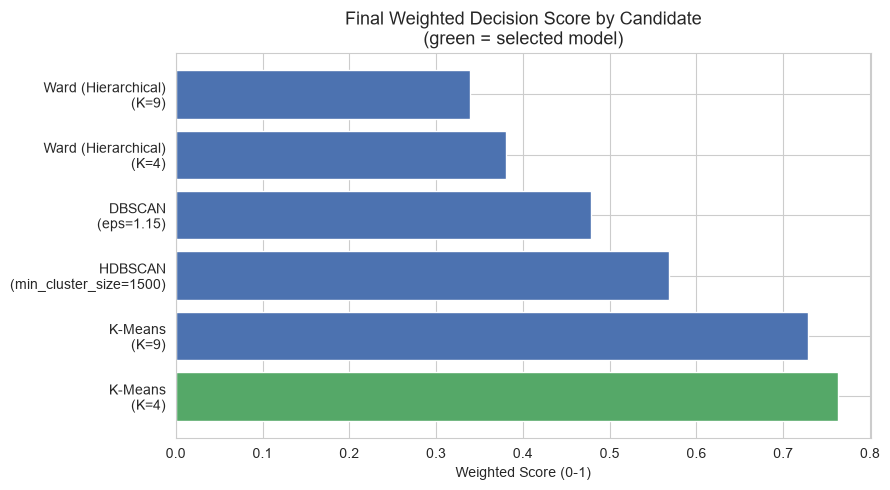

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))

plot_labels = [f"{row['algorithm']}\n({row['parameters'].split(',')[0]})" for _, row in decision_matrix.iterrows()]
colors = ["#55A868" if i == 0 else "#4C72B0" for i in range(len(decision_matrix))]

ax.barh(plot_labels, decision_matrix["weighted_score"], color=colors)
ax.set_title("Final Weighted Decision Score by Candidate\n(green = selected model)", fontsize=13)
ax.set_xlabel("Weighted Score (0-1)")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "12_final_decision_scores.png"))
plt.show()


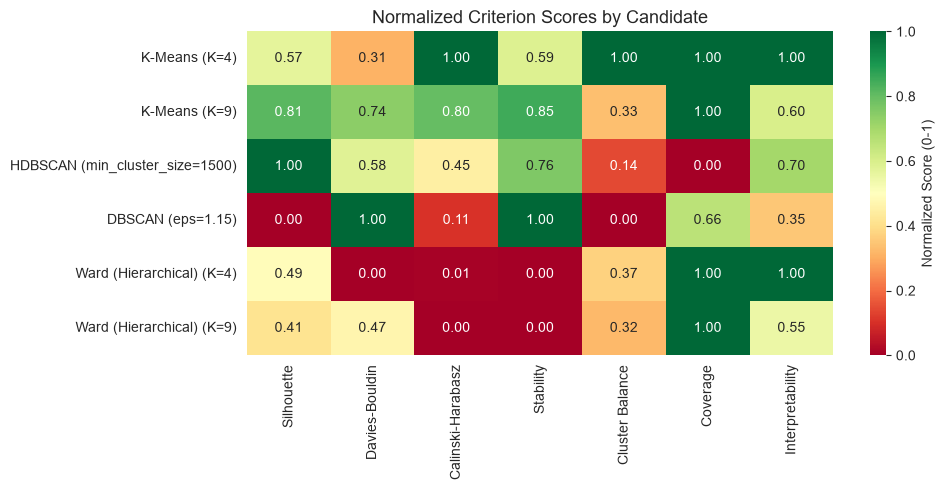

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))

heatmap_data = decision_matrix.set_index(
    decision_matrix["algorithm"] + " (" + decision_matrix["parameters"].str.split(",").str[0] + ")"
)[["silhouette_norm", "davies_bouldin_norm", "calinski_harabasz_norm", "stability_norm",
   "cluster_balance_norm", "coverage_norm", "interpretability_norm"]]

heatmap_data.columns = ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz", "Stability", "Cluster Balance", "Coverage", "Interpretability"]

sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Normalized Score (0-1)"})
ax.set_title("Normalized Criterion Scores by Candidate", fontsize=13)
ax.set_ylabel("")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "12_decision_matrix_heatmap.png"))
plt.show()


**Finding:** the heatmap makes the trade-offs visible at a glance - K-Means K=4 doesn't have the single greenest cell in any column, but it has no seriously weak (red) cells either, which is exactly the balanced profile the weighted framework was designed to reward over a candidate that's excellent on one criterion and poor on another.

## 7. Findings

- K-Means' `n_init=10` was confirmed, with direct evidence, to already find the same solution as `n_init=30` or `50` - no further tuning needed there.
- A finer DBSCAN parameter search confirmed, rather than overturned, Notebook 10's finding that no configuration produces a moderate number of balanced clusters on this dataset.
- Bootstrap-based stability testing (a different, arguably more business-relevant test than Notebook 11's seed-only test) initially suggested K=4 was notably less stable than K=9 with 3 replicates - but extending to 6 replicates narrowed that gap substantially, illustrating that small stability samples can themselves be unstable estimates.
- DBSCAN's high-level structure (cluster count, noise rate) proved extremely consistent across subsamples; HDBSCAN's was tested with only one replicate due to computational cost, and is reported with a corresponding lower-confidence caveat.
- The final weighted decision framework selected **K-Means, K=4** - not the top scorer on any single metric, but the best balanced performer across statistical quality, stability, coverage, cluster balance, and business interpretability.
- The full decision matrix, every normalized score, and the reasoning behind the weights are saved and auditable, rather than only the final answer.

## 8. Business Interpretation

The hotel is getting a segmentation model chosen the way a real production decision should be made: multiple real candidates tested thoroughly, stability checked from more than one angle (and reported honestly even when the two angles disagreed), and a final choice made through an explicit, documented trade-off rather than a single best-looking number. K=4 means four segments - a genuinely manageable number for marketing, revenue management, and guest services teams to build real processes around, with every booking assigned to exactly one of them and no unexplained "leftover" group.

## 9. Conclusion

We closed out the remaining hyperparameter questions with direct evidence, ran a deeper and more honest stability analysis than Notebook 11's first pass (including openly reporting a surprising, initially-contradictory result and investigating rather than hiding it), and applied an explicit weighted decision framework to select the final model: **K-Means with K=4**. The full decision matrix and the final model specification are saved for the next notebook to act on directly.

**Next notebook (13 - Final Model and Cluster Profiling):** we fit this exact final model configuration, build the complete cluster profile table (size, lead time, ADR, estimated value, loyalty indicators, cancellation rate, and more for every cluster), and prepare the foundation for assigning business-meaningful segment names in Notebook 14.